# Week 08 — X-ray & CT Image Formation

Introduction to **X-ray imaging** and **computed tomography (CT)**: radiographs vs tomographic
slices, the **Beer–Lambert law** and the **linear attenuation coefficient** $\mu$, the
**energy–wavelength** relationship ($E=h\nu$), **beam hardening** (soft vs hard tissue contrast),
and reconstructing a CT slice from projections via the **Radon transform**.

Key contrast with MRI: a **radiograph is a projection** — the cumulative attenuation through the
*entire* volume along the beam — whereas an MRI (or a CT slice) represents a single **tomographic
plane**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.data import shepp_logan_phantom
from skimage.transform import radon, iradon, resize

## 1. Radiograph = a projection (sum of attenuation along the beam)
A planar radiograph has **no depth information**: every point is the accumulated attenuation of
*everything* between the X-ray source and the detector. Mathematically a projection is the **sum of
the attenuation** along the beam direction.

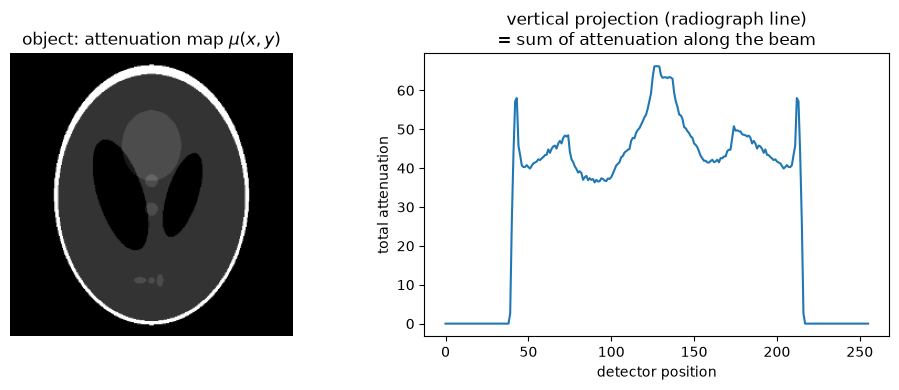

In [2]:
mu_map = resize(shepp_logan_phantom(), (256, 256), anti_aliasing=True)  # attenuation map (a.u.)
projection = mu_map.sum(axis=0)        # vertical projection = sum of columns = a 'radiograph line'

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(mu_map, cmap="gray"); ax[0].set_title("object: attenuation map $\\mu(x,y)$"); ax[0].axis("off")
ax[1].plot(projection, color="tab:blue")
ax[1].set_title("vertical projection (radiograph line)\n= sum of attenuation along the beam")
ax[1].set_xlabel("detector position"); ax[1].set_ylabel("total attenuation")
plt.tight_layout(); plt.show()

## 2. The Beer–Lambert law
As a beam of incident intensity $I_0$ passes through tissue, each thin slab $dx$ removes a fraction
proportional to the **linear attenuation coefficient** $\mu$:
$$dI = -\mu\, I\, dx \;\Rightarrow\; \frac{dI}{I} = -\mu\,dx \;\Rightarrow\; I = I_0\,e^{-\int \mu\,dx}.$$
For a uniform material of thickness $L$: $I = I_0 e^{-\mu L}$. $\mu$ (units cm$^{-1}$) is the X-ray
analogue of “magnetization per unit volume” in MRI — it is the tissue property that forms contrast.

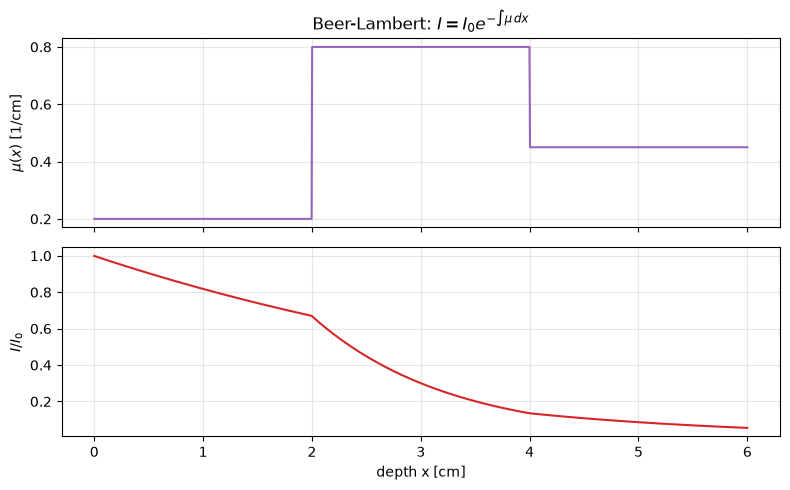

transmitted fraction I/I0 = 0.0549  (the rest is absorbed/scattered)


In [3]:
# Beam passing through three stacked slabs of different attenuation
x = np.linspace(0, 6, 1200)                 # depth [cm]
mu = np.piecewise(x,
                  [x < 2, (x >= 2) & (x < 4), x >= 4],
                  [0.2, 0.8, 0.45])          # mu per region [1/cm]: soft, bone, soft
I0 = 1.0
dx = x[1] - x[0]
I = I0 * np.exp(-np.cumsum(mu) * dx)         # Beer-Lambert attenuation along the path

fig, ax = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
ax[0].plot(x, mu, color="tab:purple"); ax[0].set_ylabel(r"$\mu(x)$ [1/cm]")
ax[0].set_title("Beer-Lambert: $I = I_0 e^{-\\int \\mu\\,dx}$")
ax[1].plot(x, I, color="tab:red"); ax[1].set_ylabel("$I/I_0$"); ax[1].set_xlabel("depth x [cm]")
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"transmitted fraction I/I0 = {I[-1]:.4f}  (the rest is absorbed/scattered)")

## 3. Energy and wavelength: $E = h\nu = hc/\lambda$
X-rays sit at the high-energy end of the electromagnetic spectrum. Since $\nu = c/\lambda$,
$$E = h\nu = \frac{hc}{\lambda}.$$
**Short wavelength → high energy**, and a wave can resolve gaps comparable to its wavelength — so
resolving tiny features (a virus) needs very high energy; large features (a mouse) need far less.
High-energy X-rays are also more **ionizing** than low-energy radio waves.

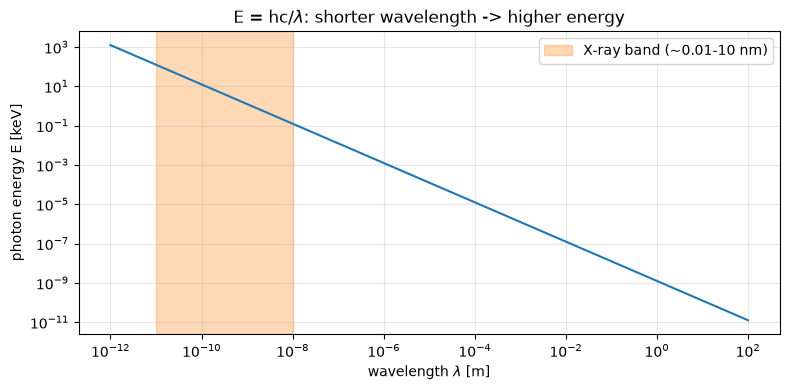

lambda =  0.03 nm  ->  E =    41.4 keV
lambda =   0.1 nm  ->  E =    12.4 keV
lambda =   1.0 nm  ->  E =     1.2 keV


In [4]:
h = 6.626e-34      # Planck constant [J s]
c = 3.0e8          # speed of light [m/s]
keV = 1.602e-16    # 1 keV in joules

lam = np.logspace(-12, 2, 500)     # wavelength [m]: 1 pm (gamma/X-ray) up to 100 m (radio)
E_keV = (h * c / lam) / keV        # photon energy [keV]

plt.figure(figsize=(8, 4))
plt.loglog(lam, E_keV, color="tab:blue")
plt.axvspan(1e-11, 1e-8, color="tab:orange", alpha=0.3, label="X-ray band (~0.01-10 nm)")
plt.xlabel("wavelength $\\lambda$ [m]"); plt.ylabel("photon energy E [keV]")
plt.title("E = hc/$\\lambda$: shorter wavelength -> higher energy")
plt.legend(); plt.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()

for nm in (0.03, 0.1, 1.0):        # a few X-ray wavelengths
    print(f"lambda = {nm:>5} nm  ->  E = {(h*c/(nm*1e-9))/keV:7.1f} keV")

## 4. Beam hardening: soft-tissue vs bone contrast
The attenuation coefficient **falls as photon energy rises** (and bone, high atomic number, attenuates
far more than soft tissue at low energy). Consequences (the “two mice” example):
- **High-energy (“hardened”) beam:** blitzes through soft tissue (negligible attenuation) → only
  **bone** shows up. Use a hardened beam to image **hard tissue**.
- **Low-energy (“softer”) beam:** even soft tissue attenuates appreciably → soft-tissue contrast
  appears (but more dose/whitening). Use a softer beam to image **soft tissue**.

(The $\mu(E)$ curves below are illustrative, capturing the photoelectric $\sim 1/E^3$ falloff.)

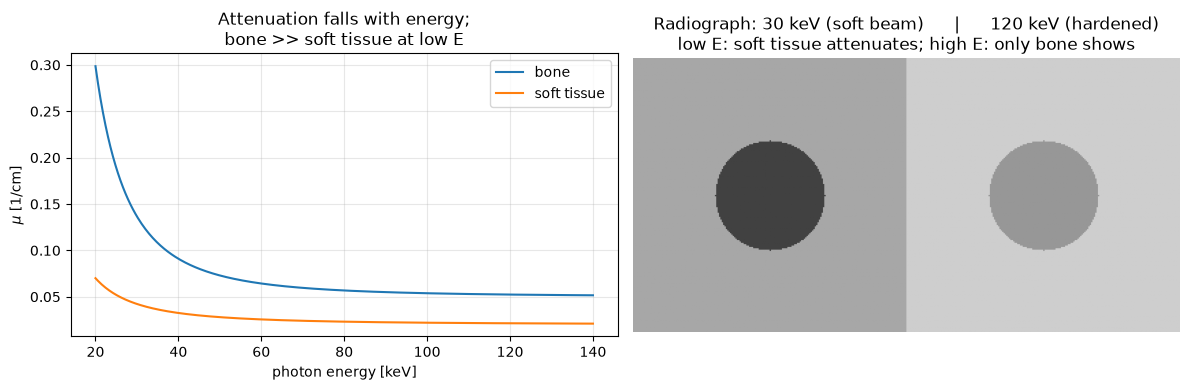

In [5]:
E = np.linspace(20, 140, 400)              # photon energy [keV]
mu_soft = 0.02 + 20.0 / E ** 2.0           # soft tissue (illustrative) [1/cm]
mu_bone = 0.05 + 600.0 / E ** 2.6          # bone: much higher at low E (high Z) [1/cm]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(E, mu_bone, label="bone", color="tab:blue")
ax[0].plot(E, mu_soft, label="soft tissue", color="tab:orange")
ax[0].set_xlabel("photon energy [keV]"); ax[0].set_ylabel(r"$\mu$ [1/cm]")
ax[0].set_title("Attenuation falls with energy;\nbone >> soft tissue at low E"); ax[0].legend(); ax[0].grid(alpha=0.3)

# Two 'radiographs' of a soft-tissue block containing a bone disk, at low vs high energy
N = 200
yy, xx = np.mgrid[0:N, 0:N]
bone_mask = (xx - N/2) ** 2 + (yy - N/2) ** 2 <= (N/5) ** 2
L = 10.0                                    # path length [cm]

def radiograph(E_keV):
    ms = 0.02 + 20.0 / E_keV ** 2.0
    mb = 0.05 + 600.0 / E_keV ** 2.6
    mu_img = np.where(bone_mask, mb, ms)
    return np.exp(-mu_img * L)              # transmitted intensity (bright = more X-rays through)

low, high = radiograph(30), radiograph(120)
ax[1].imshow(np.hstack([low, high]), cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Radiograph: 30 keV (soft beam)      |      120 keV (hardened)\n"
                "low E: soft tissue attenuates; high E: only bone shows")
ax[1].axis("off")
plt.tight_layout(); plt.show()

## 5. From projections to a tomographic slice (CT = Radon transform)
A single X-ray gives one projection. Collecting projections at many angles (0–180°) and applying the
**inverse Radon transform** (filtered back-projection) reconstructs a **tomographic slice** of
$\mu(x,y)$ — exactly the projection-reconstruction idea (Nobel Prize, 1979) used for CT, mirroring
the k-space projection method for MRI.

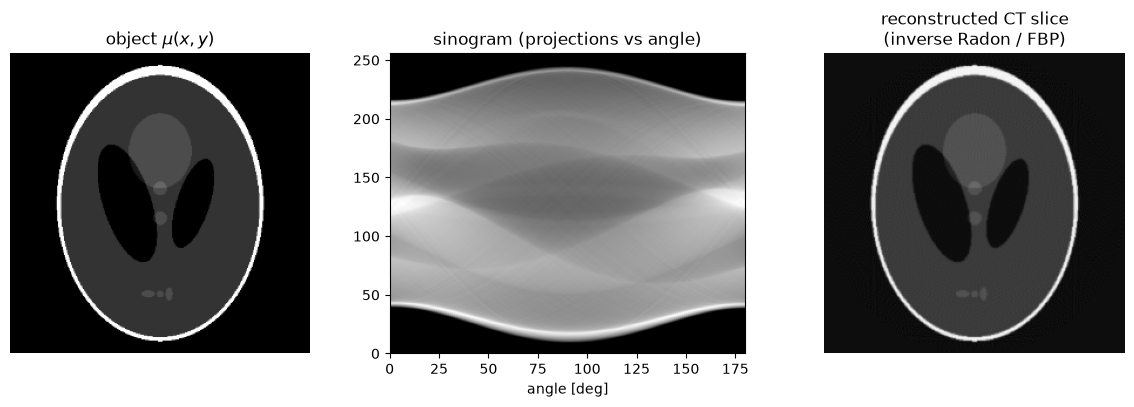

In [6]:
angles = np.arange(0, 180, 1.0)
sinogram = radon(mu_map, theta=angles)                    # X-ray projections at each angle
ct_slice = iradon(sinogram, theta=angles, filter_name="ramp")  # filtered back-projection

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(mu_map, cmap="gray"); ax[0].set_title("object $\\mu(x,y)$"); ax[0].axis("off")
ax[1].imshow(sinogram, cmap="gray", aspect="auto", extent=(0, 180, 0, sinogram.shape[0]))
ax[1].set_title("sinogram (projections vs angle)"); ax[1].set_xlabel("angle [deg]")
ax[2].imshow(ct_slice, cmap="gray"); ax[2].set_title("reconstructed CT slice\n(inverse Radon / FBP)"); ax[2].axis("off")
plt.tight_layout(); plt.show()

## Takeaways
- A **radiograph is a projection** (Beer–Lambert attenuation summed through the whole volume); a **CT
  slice** is tomographic (one plane), reconstructed from many projections via the **Radon transform**.
- **Beer–Lambert:** $I = I_0 e^{-\int \mu\,dx}$; $\mu$ (linear attenuation coefficient) is the tissue
  property that creates contrast.
- **$E = hc/\lambda$:** higher energy = shorter wavelength = resolves finer gaps, but more ionizing.
- **Beam hardening:** hardened (high-E) beams image **bone** (soft tissue transparent); softer (low-E)
  beams are needed for **soft-tissue** contrast.
- X-ray/CT: **very high spatial resolution** but **poor soft-tissue contrast**; the go-to when MRI is
  contraindicated (e.g. metal implants).